<a href="https://colab.research.google.com/github/nabasalim/appointment-booking-system/blob/main/GPU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

100%|██████████| 806M/806M [00:37<00:00, 22.5MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/saadpd/menwomen-classification/versions/1
Found 3377 images belonging to 2 classes.
Found 844 images belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 125s 1s/step - accuracy: 0.5867 - loss: 0.7969 - val_accuracy: 0.6765 - val_loss: 0.6269
Epoch 2/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 82s 771ms/step - accuracy: 0.6427 - loss: 0.6866 - val_accuracy: 0.7085 - val_loss: 0.6105
Epoch 3/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 83s 778ms/step - accuracy: 0.6069 - loss: 0.6932 - val_accuracy: 0.6872 - val_loss: 0.6437
Epoch 4/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 82s 779ms/step - accuracy: 0.6508 - loss: 0.6683 - val_accuracy: 0.7073 - val_loss: 0.5879
Epoch 5/5
106/106 ━━━━━━━━━━━━━━━━━━━━ 83s 783ms/step - accuracy: 0.6485 - loss: 0.6648 - val_accuracy: 0.6908 - val_loss: 0.6261


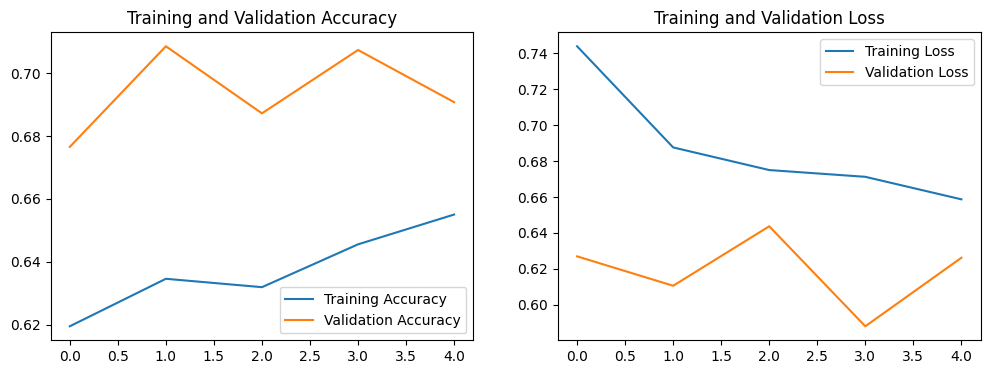

In [1]:
# --- TASK 1a: Implementation of Binary Image Classification ---

# Step 1: Install and import necessary libraries
!pip install kagglehub  # Ensure kagglehub is installed in Colab
import kagglehub
import os
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Step 2: Download the dataset from Kaggle using kagglehub
# This will download and extract the 'Men-Women Classification' dataset automatically
path = kagglehub.dataset_download("saadpd/menwomen-classification")
print("Dataset downloaded to:", path)

# Step 3: Data Preprocessing and Augmentation
# We use ImageDataGenerator to normalize images and split them into training and validation sets
datagen = ImageDataGenerator(
    rescale=1./255,           # Normalize pixel values to [0, 1]
    validation_split=0.2,      # Use 20% of data for validation
    horizontal_flip=True,      # Data augmentation to prevent overfitting
    rotation_range=20
)

# Load training data
train_generator = datagen.flow_from_directory(
    path,
    target_size=(224, 224),    # Resize images to 224x224 for MobileNetV2
    batch_size=32,
    class_mode='binary',       # Binary classification (Men vs Women)
    subset='training'
)

# Load validation data
validation_generator = datagen.flow_from_directory(
    path,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

# Step 4: Build the Model using Transfer Learning (MobileNetV2)
# Load pre-trained MobileNetV2 without the top classification layer
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze the pre-trained weights

# Add custom classification head
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),      # Dropout layer to mitigate overfitting (as required in report)
    layers.Dense(1, activation='sigmoid') # Sigmoid for binary output
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Show model summary (Capture a screenshot of this output for your report)
model.summary()

# Step 5: Train the Model
# Training for 5 epochs for demonstration (you can increase this for better accuracy)
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=5
)

# Step 6: Evaluate and Plot Results (Capture a screenshot of these plots)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()